# 12 · Surplomb et auto-support

*Notebook 12 du cours. Il suppose le notebook 9 (le pipeline densité → filtre → projection) et utilise l'optimiseur MMA du notebook 10.*

Jusqu'ici la forme optimale est celle qu'on aurait si l'on pouvait placer de la matière n'importe où. Une imprimante FDM ne le peut pas : elle dépose du plastique **couche par couche**, et le filament fraîchement extrudé doit reposer sur quelque chose. Une matière qui flotte au-dessus du vide s'affaisse. Les formes que l'optimisation topologique aime (arches, bielles presque horizontales, semelles en porte-à-faux) sont souvent exactement celles-là. Les imprimer demande des **supports** : de la matière sacrifiée, à retirer ensuite, qui coûte du plastique, du temps et un état de surface dégradé.

L'idée de ce notebook : mettre la règle « la pièce se tient toute seule » **dans** l'optimisation, pour que la forme trouvée n'ait pas besoin de supports.

**Plan.**
1. La règle exacte d'auto-support et ce qu'elle retire ;
2. Pourquoi il faut la rendre lisse, et comment (max et min lisses) ;
3. Le stencil : la croix et non le carré en 3D ;
4. Validation : oracle, majoration, gradient, cône de dépendance ;
5. Dans le pipeline, et avec la continuation ;
6. Optimisation avec et sans surplomb : ce que ça coûte ;
7. Bilan.

**Code promu dans `src`.** `topopt/overhang.py` (`OverhangParams`, `shifted_stack`, `smax`, `smin`, `overhang_filter`, `check_solid_supported`) ; `DensityPipeline` et `ComplianceProblem` acceptent l'option `overhang`. Oracle indépendant : `tests/reference/overhang_numpy.py::exact_support` (boucles explicites). Contrats : C-OVH-01 à 09.

In [1]:
import sys, math, time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir())
sys.path.insert(0, str(RACINE / "src"))
sys.path.insert(0, str(RACINE / "tests"))

from aeroptimizer.optim.continuation import Schedule
from aeroptimizer.optim.loop import run
from aeroptimizer.optim.mma import MMA
from aeroptimizer.optim.oc import OC
from aeroptimizer.problem import ComplianceProblem
from aeroptimizer.topopt.overhang import OverhangParams, overhang_filter, shifted_stack, smax, smin
from reference.overhang_numpy import exact_support       # oracle indépendant : règle exacte, boucles explicites

torch.set_default_dtype(torch.float64)       # convention du projet (CONTRACTS C-CONV-03)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

def montre(ax, rho, titre="", cmap="gray_r"):
    # champ 2D (nx, nz) : x vers la droite, z (axe de fabrication) vers le haut
    ax.imshow(np.asarray(rho).T, origin="lower", cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(titre, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

## 1. La règle exacte d'auto-support

Convention du projet : l'**axe de fabrication est le dernier axe** (en 2D, $z$ vers le haut). La couche $\ell=0$ est le plateau d'impression, toujours supportée. Une cellule de la couche $\ell\ge1$ est **imprimée** si (a) elle est dans la forme voulue **et** (b) au moins une cellule de son **stencil** dans la couche $\ell-1$ est elle-même imprimée. En 2D, le stencil est $\{c-1,c,c+1\}$ : une cellule peut reposer sur la cellule d'en dessous ou sur ses deux voisines en diagonale.

Que dit cette règle de l'angle ? Si une frontière avance d'**une** cellule par couche, sa pente est de $45^\circ$ par rapport à la verticale ; c'est la limite usuelle du FDM. Avec un stencil d'une cellule, **seul $45^\circ$ est représentable** (FORMALISM H5). Tout angle plus plat est retiré. Les **ponts**, c'est-à-dire des travées horizontales posées sur deux piliers, sont aussi retirés au-delà d'une cellule : en pratique une imprimante sait ponter quelques centimètres, la règle est donc **conservatrice** (hypothèse H5 du projet).

L'oracle `exact_support` écrit cette règle avec des boucles, couche par couche. On l'applique à quatre formes.

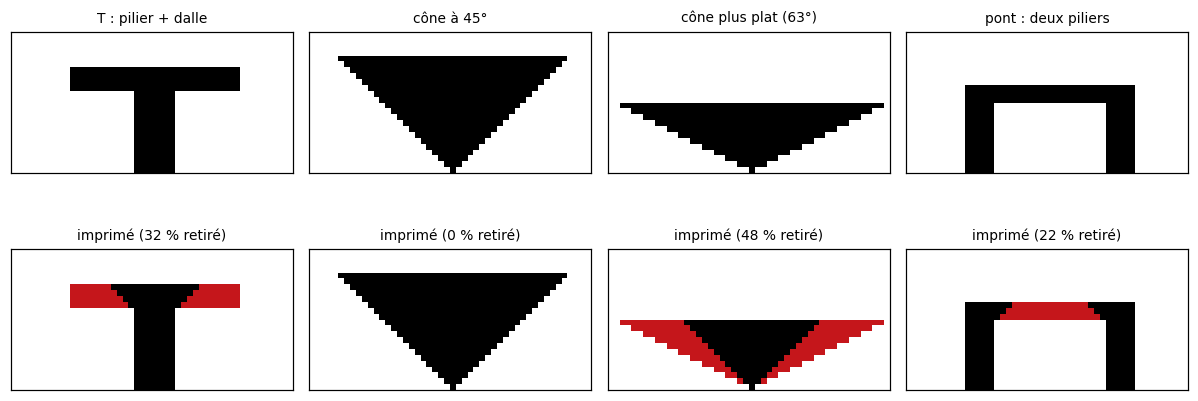

In [2]:
nx, nz = 48, 24
X, Z = np.meshgrid(np.arange(nx), np.arange(nz), indexing="ij")

formes = {
    "T : pilier + dalle":      ((np.abs(X - 24) <= 3) & (Z < 14)) | ((Z >= 14) & (Z < 18) & (np.abs(X - 24) <= 14)),
    "cône à 45°":              (np.abs(X - 24) <= Z // 1) & (Z < 20),
    "cône plus plat (63°)":    (np.abs(X - 24) <= 2 * Z) & (Z < 12),
    "pont : deux piliers":     ((np.abs(X - 12) <= 2) | (np.abs(X - 36) <= 2)) & (Z < 12) | ((Z >= 12) & (Z < 15) & (np.abs(X - 24) <= 14)),
}
fig, axs = plt.subplots(2, 4, figsize=(11, 4.6))
for j, (nom, f) in enumerate(formes.items()):
    out = exact_support(f)
    montre(axs[0, j], f, nom)
    retire = f & ~out
    montre(axs[1, j], out + 0.0, f"imprimé ({100*retire.sum()/f.sum():.0f} % retiré)")
    axs[1, j].imshow(np.where(retire, 1.0, np.nan).T, origin="lower", cmap="Reds", vmin=0, vmax=1.3, interpolation="nearest")
plt.tight_layout(); plt.show()

Le cône à $45^\circ$ est intact : sa frontière avance d'une cellule par couche. La dalle du « T » est retirée sauf un triangle à $45^\circ$ sous elle (en rouge : la matière retirée), et le pont est coupé en deux consoles à $45^\circ$ qui ne se rejoignent pas : c'est le conservatisme assumé. Un cône plus plat que $45^\circ$ perd tout ce qui dépasse.

Cette règle est **parfaite pour vérifier** une forme, mais inutilisable **pour optimiser** : elle prend des valeurs binaires et sa « dérivée » est nulle presque partout. Il nous faut une version lisse qui coïncide avec elle à la limite.

## 2. Une version lisse : max et min lisses

La règle s'écrit avec deux opérations : « il existe un voisin imprimé en dessous » (un **max** sur le stencil) et « la cellule est voulue **et** supportée » (un **min**). Pour des valeurs dans $[0,1]$ :

$$
\xi_0=\hat\rho_0,\qquad
\Xi_\ell(c)=\mathrm{smax}_{c'\in\mathcal{N}(c)}\ \xi_{\ell-1}(c'),\qquad
\xi_\ell(c)=\mathrm{smin}_\epsilon\big(\hat\rho_\ell(c),\,\Xi_\ell(c)\big),\qquad
\bar\rho=\xi .
$$

On remplace le max par le **log-somme-exponentielle** et le min de deux nombres par une **racine régularisée** :

$$
\mathrm{smax}_{\beta_s}(y_1..y_n)=\frac{1}{\beta_s}\log\sum_k e^{\beta_s y_k}-\frac{\log n}{\beta_s},\qquad
\mathrm{smin}_\epsilon(a,b)=\tfrac{1}{2}\Big(a+b-\sqrt{(a-b)^2+\epsilon}+\sqrt{\epsilon}\Big).
$$

**Propriétés** (toutes vérifiables) :
- $\mathrm{smax}\le\max$ et $\max-\mathrm{smax}\le\log n/\beta_s$ : le max lisse **sous-estime** d'au plus $\log n/\beta_s$ (le terme $-\log n/\beta_s$ est là pour que $\mathrm{smax}(1,\dots,1)=1$ exactement) ;
- $\mathrm{smin}\le\min+\sqrt{\epsilon}/2$ ;
- les deux sont **croissants** par rapport à chaque argument, donc $\bar\rho$ l'est par rapport à $\hat\rho$ : le filtre ne change jamais le signe de la sensibilité ;
- $\bar\rho\le\hat\rho$ à la tolérance près : **le filtre ne crée jamais de matière**, il en retire.

On préfère le log-somme-exponentielle à la $P$-norme de la littérature (Langelaar) parce que son gradient est **fini partout**, même quand toutes les entrées sont nulles ; la $P$-norme a une dérivée infinie en $0$.

In [3]:
# smax : le biais est borné par log(n)/beta ; smin : l'erreur est au plus sqrt(eps)/2
g = torch.Generator().manual_seed(0)
print(f"{'n':>3} {'beta':>6} {'biais max mesuré':>18} {'borne log(n)/beta':>18}")
for n in (3, 5):
    for beta in (10.0, 50.0, 200.0):
        y = torch.rand(20000, n, generator=g)
        biais = float((y.max(-1).values - smax(y, beta)).max())
        print(f"{n:>3} {beta:>6.0f} {biais:>18.5f} {math.log(n)/beta:>18.5f}")
print("smax(1,1,1) =", float(smax(torch.ones(3), 10.0)), "  smax(0,0,0) =", float(smax(torch.zeros(3), 10.0)))

a, b = torch.rand(20000, generator=g), torch.rand(20000, generator=g)
for eps in (1e-2, 1e-4, 1e-8):
    err = float((smin(a, b, eps) - torch.minimum(a, b)).abs().max())
    print(f"eps = {eps:.0e} : |smin - min| max = {err:.5f}   (sqrt(eps)/2 = {math.sqrt(eps)/2:.5f})")

  n   beta   biais max mesuré  borne log(n)/beta
  3     10            0.10985            0.10986
  3     50            0.02197            0.02197
  3    200            0.00549            0.00549
  5     10            0.16090            0.16094
  5     50            0.03219            0.03219
  5    200            0.00805            0.00805
smax(1,1,1) = 0.9999999999999999   smax(0,0,0) = 0.0
eps = 1e-02 : |smin - min| max = 0.04749   (sqrt(eps)/2 = 0.05000)
eps = 1e-04 : |smin - min| max = 0.00497   (sqrt(eps)/2 = 0.00500)
eps = 1e-08 : |smin - min| max = 0.00005   (sqrt(eps)/2 = 0.00005)


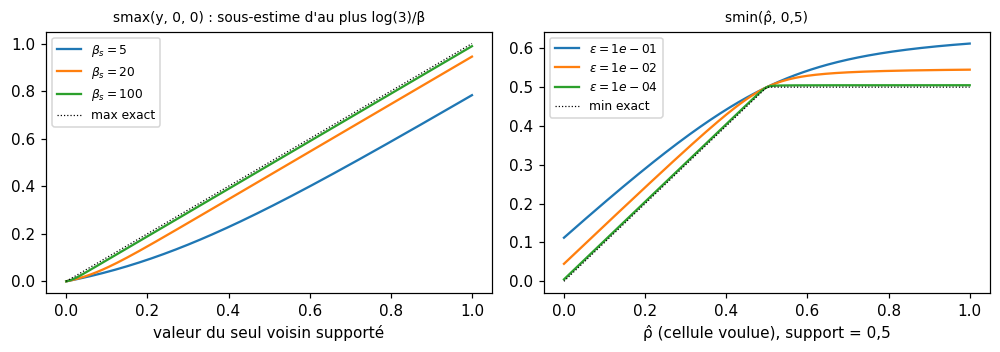

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(9.2, 3.3))
y = torch.linspace(0, 1, 201)
for beta in (5.0, 20.0, 100.0):
    # max de (y, 0, 0) : une cellule supportée sur trois
    axs[0].plot(y, smax(torch.stack([y, 0 * y, 0 * y], -1), beta), label=rf"$\beta_s={beta:.0f}$")
axs[0].plot(y, y, "k:", lw=0.8, label="max exact"); axs[0].set_xlabel("valeur du seul voisin supporté")
axs[0].set_title("smax(y, 0, 0) : sous-estime d'au plus log(3)/β", fontsize=9); axs[0].legend(fontsize=8)
for eps in (1e-1, 1e-2, 1e-4):
    axs[1].plot(y, smin(y, torch.full_like(y, 0.5), eps), label=rf"$\epsilon={eps:.0e}$")
axs[1].plot(y, torch.minimum(y, torch.tensor(0.5)), "k:", lw=0.8, label="min exact")
axs[1].set_xlabel("ρ̂ (cellule voulue), support = 0,5"); axs[1].set_title("smin(ρ̂, 0,5)", fontsize=9); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Le stencil : la croix, pas le carré

En 3D, la couche est une grille $(x,y)$ et il faut choisir quelles cellules du dessous peuvent supporter. Le choix naturel est le carré $3\times3$ (les 8 voisines et la cellule du dessous). C'est une erreur : une frontière **diagonale** avance alors de $\sqrt2\,h$ par couche, soit $\arctan\sqrt2\approx54{,}7^\circ$ : la règle laisserait passer des surplombs plus plats que $45^\circ$.

Avec la **croix à 5 points** $\{c,\ c\pm\mathbf e_x,\ c\pm\mathbf e_y\}$, la frontière avance d'une cellule par couche le long des axes ($45^\circ$) et de $h/\sqrt2$ le long des diagonales ($\arctan(1/\sqrt2)\approx35{,}3^\circ$ : plus strict que nécessaire). La contrainte $\theta\le45^\circ$ est donc respectée dans **toutes** les directions horizontales, de façon conservatrice sur les diagonales.

On le mesure : une seule cellule sur le plateau, tout le reste de la forme voulu. La région imprimée est le **cône atteignable** ; on mesure sa portée horizontale à chaque couche.

couche  portée croix  portée carré  angle croix  angle carré
     1          1.00          1.41        45.0°        54.7°
     2          2.00          2.83        45.0°        54.7°
     3          3.00          4.24        45.0°        54.7°
     4          4.00          5.66        45.0°        54.7°
     5          5.00          7.07        45.0°        54.7°
     6          6.00          8.49        45.0°        54.7°
     7          7.00          9.90        45.0°        54.7°
     8          8.00         11.31        45.0°        54.7°


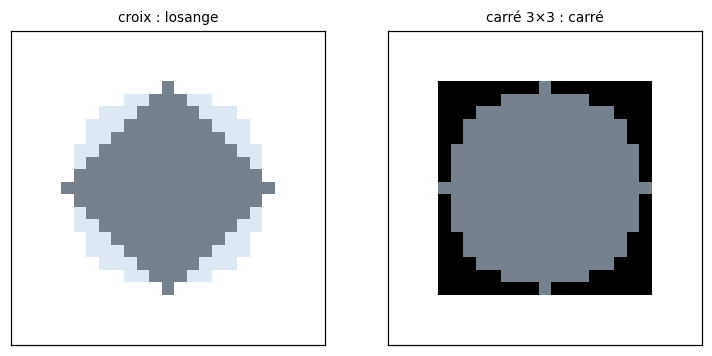

In [5]:
from scipy import ndimage
n, couches = 25, 9
rho = np.ones((n, n, couches), bool); rho[..., 0] = False; rho[n//2, n//2, 0] = True
cone = exact_support(rho)                                   # stencil en croix
ii, jj = np.meshgrid(np.arange(n) - n//2, np.arange(n) - n//2, indexing="ij")
dist = np.sqrt(ii**2 + jj**2)
carre = np.zeros((n, n), bool); carre[n//2, n//2] = True    # stencil carré 3x3, pour comparer
print(f"{'couche':>6} {'portée croix':>13} {'portée carré':>13} {'angle croix':>12} {'angle carré':>12}")
for l in range(1, couches):
    carre = ndimage.binary_dilation(carre, structure=np.ones((3, 3)))
    rc, rs = dist[cone[..., l]].max(), dist[carre].max()
    print(f"{l:>6} {rc:>13.2f} {rs:>13.2f} {math.degrees(math.atan(rc/l)):>11.1f}° {math.degrees(math.atan(rs/l)):>11.1f}°")

fig, axs = plt.subplots(1, 2, figsize=(7, 3.3))
montre(axs[0], cone[..., couches - 1], "croix : losange"); montre(axs[1], carre, "carré 3×3 : carré")
for ax in axs: ax.imshow(np.where(dist <= couches - 1, 0.25, np.nan).T, origin="lower", cmap="Blues", vmin=0, vmax=1, alpha=0.6)
plt.tight_layout(); plt.show()

La croix reste à $45^\circ$ dans la direction des axes (portée $=\ell$) et le carré fait **$54{,}7^\circ$** dans la diagonale (portée $\sqrt2\,\ell$). Le disque bleu est la limite $45^\circ$ : le carré le dépasse dans ses coins, le losange de la croix reste à l'intérieur.

## 4. Validation

**(a) Contre l'oracle.** Pour une entrée binaire et $\beta_s$ grand, le filtre lisse doit retrouver la règle exacte. Mais le biais de $\mathrm{smax}$, $\log n/\beta_s$, est payé **à chaque couche** quand un seul voisin supporte la cellule (une frontière à $45^\circ$) : l'erreur s'accumule le long du cône. On prédit une erreur $\approx(n_z-1)\log n/\beta_s$ avec $n=3$ en 2D, et on la mesure sur le pire cas, une marche d'escalier à $45^\circ$.

In [6]:
def escalier(nz, nx=None):
    # une colonne qui se décale d'une cellule par couche : chaque cellule n'a qu'un seul support
    nx = nx or nz + 4
    f = torch.zeros(nx, nz)
    for l in range(nz): f[2 + l, l] = 1.0
    return f

print(f"{'couches':>8} {'beta_s':>7} {'erreur sommet':>14} {'(nz-1) log3/beta':>17}")
for nzz in (6, 12, 24):
    f = escalier(nzz)
    for bs in (50.0, 200.0, 1000.0):
        out = overhang_filter(f, OverhangParams(beta_s=bs, eps=1e-10))
        err = 1.0 - float(out[2 + nzz - 1, nzz - 1])
        print(f"{nzz:>8} {bs:>7.0f} {err:>14.4f} {(nzz-1)*math.log(3)/bs:>17.4f}")

print("\nÉcart maximal à l'oracle sur champs aléatoires binaires (3D, 8 couches), eps = 1e-10 :")
rng = torch.Generator().manual_seed(0)
for bs in (50.0, 200.0, 1000.0, 3000.0):
    ecart = 0.0
    for _ in range(4):
        r = (torch.rand(7, 6, 8, generator=rng) < 0.6).double()
        ecart = max(ecart, float((overhang_filter(r, OverhangParams(beta_s=bs, eps=1e-10)) - torch.from_numpy(exact_support(r.numpy())*1.0)).abs().max()))
    print(f"  beta_s = {bs:>6.0f} : {ecart:.4f}")

 couches  beta_s  erreur sommet  (nz-1) log3/beta
       6      50         0.1098            0.1099
       6     200         0.0274            0.0275
       6    1000         0.0055            0.0055
      12      50         0.2416            0.2417
      12     200         0.0604            0.0604
      12    1000         0.0120            0.0121
      24      50         0.5052            0.5054
      24     200         0.1262            0.1263
      24    1000         0.0252            0.0253

Écart maximal à l'oracle sur champs aléatoires binaires (3D, 8 couches), eps = 1e-10 :
  beta_s =     50 : 0.1510
  beta_s =    200 : 0.0431
  beta_s =   1000 : 0.0073
  beta_s =   3000 : 0.0024


L'erreur de l'escalier (le pire cas) **égale** la prédiction à trois chiffres ; sur des champs aléatoires elle reste sous cette borne (0,15 contre 0,23 pour $\beta_s=50$ et 7 couches en 3D). **Conséquence pratique :** $\beta_s$ doit croître avec le nombre de couches ($\gtrsim n_z\log n/\text{tolérance}$) ; avec 20 couches et 1 % de tolérance il faut $\beta_s\approx 5000$, bien au-delà des 80 de la continuation. Le filtre lisse n'est donc **pas** exact aux valeurs de $\beta_s$ de l'optimisation ; on lui demande seulement d'être auto-supportant **après binarisation à 0,5**, ce qui se vérifie à part (b).

**(b) Majoration et auto-support.** Sur 100 champs aléatoires continus, on vérifie que (i) $\bar\rho\le\hat\rho+\sqrt{\epsilon}$ et que (ii) la sortie binarisée à $0{,}5$ est un point fixe de la règle exacte (aucune cellule imprimée n'est sans support).

In [7]:
params = OverhangParams(beta_s=50.0, eps=1e-10)
g = torch.Generator().manual_seed(1)
pire_exces, violations, retire = -1.0, 0, []
for k in range(100):
    shape = (14, 10) if k % 2 == 0 else (6, 6, 8)
    rho = torch.rand(shape, generator=g)
    out = overhang_filter(rho, params)
    pire_exces = max(pire_exces, float((out - rho).max()))
    b = (out > 0.5).numpy()
    violations += int((exact_support(b) != b).sum())
    retire.append(float(((rho > 0.5).sum() - (out > 0.5).sum()) / (rho > 0.5).sum()))
print(f"max (rho_bar - rho_hat) sur 100 champs : {pire_exces:.2e}   (<= sqrt(eps) = {math.sqrt(1e-10):.0e})")
print(f"cellules imprimées sans support après binarisation : {violations}")
print(f"matière (>0,5) retirée sur des champs aléatoires : {100*np.mean(retire):.0f} % en moyenne")

max (rho_bar - rho_hat) sur 100 champs : 5.00e-06   (<= sqrt(eps) = 1e-05)
cellules imprimées sans support après binarisation : 0
matière (>0,5) retirée sur des champs aléatoires : 27 % en moyenne


**(c) Gradient.** Le filtre est écrit en `torch` pur : Autograd rétropropage à travers la récurrence des couches (aucune dérivée à la main). On le vérifie par `gradcheck` en 2D et 3D, et on contrôle qu'il n'y a ni NaN ni infini, même pour un champ nul.

**(d) Le cône de dépendance.** La cellule du sommet dépend de **toutes** les couches du dessous, mais seulement de celles de son **cône de support** : le gradient de $\bar\rho_{\text{sommet}}$ par rapport à $\hat\rho$ doit dessiner un triangle à $45^\circ$ (contrat C-OVH-09). C'est ce que « rétropropager à travers la boucle de couches » veut dire.

gradcheck 2D 5x5   : True
gradcheck 3D 4x4x4 : True
champ nul : gradient fini ? True   max |grad| = 1.9887760059442159


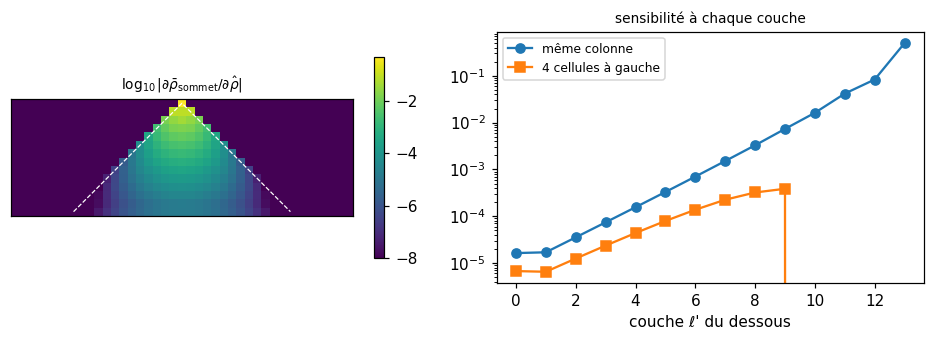

gradient hors du cône (colonnes < 7) : 0.0


In [8]:
x = torch.rand(5, 5, dtype=torch.float64, requires_grad=True)
print("gradcheck 2D 5x5   :", torch.autograd.gradcheck(lambda a: overhang_filter(a, OverhangParams(beta_s=20.0)), (x,), atol=1e-6))
x = torch.rand(4, 4, 4, dtype=torch.float64, requires_grad=True)
print("gradcheck 3D 4x4x4 :", torch.autograd.gradcheck(lambda a: overhang_filter(a, OverhangParams(beta_s=20.0)), (x,), atol=1e-6))
z = torch.zeros(8, 8, requires_grad=True); overhang_filter(z, OverhangParams()).sum().backward()
print("champ nul : gradient fini ?", bool(torch.isfinite(z.grad).all()), "  max |grad| =", float(z.grad.abs().max()))

nxx, nzz = 41, 14
x = torch.full((nxx, nzz), 0.7, requires_grad=True)
overhang_filter(x, OverhangParams(beta_s=20.0))[20, -1].backward()
G = x.grad.abs().numpy()
fig, axs = plt.subplots(1, 2, figsize=(8.6, 3.2))
im = axs[0].imshow(np.log10(G + 1e-16).T, origin="lower", cmap="viridis", vmin=-8, interpolation="nearest")
axs[0].set_title(r"$\log_{10}|\partial\bar\rho_{\rm sommet}/\partial\hat\rho|$", fontsize=9)
axs[0].plot([20 - (nzz - 1), 20, 20 + (nzz - 1)], [0, nzz - 1, 0], "w--", lw=0.8)
axs[0].set_xticks([]); axs[0].set_yticks([]); fig.colorbar(im, ax=axs[0], shrink=0.8)
axs[1].semilogy(np.arange(nzz), G[20, :], "o-", label="même colonne"); axs[1].semilogy(np.arange(nzz), G[20 - 4, :], "s-", label="4 cellules à gauche")
axs[1].set_xlabel("couche ℓ' du dessous"); axs[1].set_title("sensibilité à chaque couche", fontsize=9); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
hors = G[:20 - (nzz - 1), :].max()
print("gradient hors du cône (colonnes < 7) :", hors)

Le gradient est exactement nul hors du cône, et à l'intérieur il décroît avec la distance en couches (la sensibilité d'un sommet à une cellule du plateau est petite mais non nulle). C'est un fait important pour l'optimisation : **retirer de la matière en bas change toute la pièce au-dessus**.

## 5. Dans le pipeline

Le filtre se place **après la projection** (FORMALISM §2) :

$$
\mathbf x\ \to\ \rho\ \xrightarrow{\text{filtre densité}}\ \tilde\rho\ \xrightarrow{\text{projection}}\ \hat\rho\ \xrightarrow{\text{surplomb}}\ \bar\rho\ \xrightarrow{\text{masques}}\ \bar\rho .
$$

Trois points :
- **Ordre.** Le filtre de surplomb agit sur la densité *projetée* (presque binaire), car il applique une règle logique ; sur une densité grise sa notion de « support » serait floue.
- **Les zones passives (solides imposés) sont réimposées après le filtre**, sans quoi il retirerait un solide suspendu. Mais un solide passif qui ne repose sur rien est une **erreur de configuration** : `DensityPipeline` la détecte à l'initialisation (`check_solid_supported`, C-OVH-06). Les cellules du domaine de conception comptent comme support possible.
- **Continuation.** $\beta_s$ suit un calendrier (10 → 80, doublé tous les 50 itérations), comme $\beta$ ; l'objectif change quand il change, donc MMA est réinitialisé (leçon 10).

On vérifie la détection du solide non supporté :

In [9]:
from aeroptimizer.errors import ConfigError
from aeroptimizer.grid import Grid, Masks
from aeroptimizer.topopt.density import DensityPipeline

shape = (12, 8)
solid = torch.zeros(shape, dtype=torch.bool); void = torch.zeros(shape, dtype=torch.bool)
solid[5:7, 4] = True; void[4:8, 3] = True               # un solide posé sur du vide
masks = Masks(~(solid | void), solid, void)
try:
    DensityPipeline(Grid(shape, (1.0, 1.0)), masks, R=1.0, overhang=OverhangParams())
except ConfigError as e:
    print("ConfigError :", e)
void[4:8, 3] = False                                   # on libère le dessous : accepté
DensityPipeline(Grid(shape, (1.0, 1.0)), Masks(~(solid | void), solid, void), R=1.0, overhang=OverhangParams())
print("sans le vide dessous : accepté")

ConfigError : passive solid at cell (5, 4) has nothing to rest on (overhang)
sans le vide dessous : accepté


## 6. Optimiser avec et sans surplomb

On reprend deux cas : la poutre **MBB** ($60\times20$, fraction volumique $0{,}5$) et la **console** ($60\times30$, $0{,}4$, charge répartie sur le bord libre), avec $R=3$, la continuation en $\beta$ de 1 à 16 et en $\beta_s$ de 10 à 80. On compare avec la même optimisation sans filtre de surplomb.

Deux mesures :
- la **compliance** $C$ (le coût de la contrainte de fabrication) ;
- la fraction de cellules imprimées (densité $>0{,}5$) **sans support** selon la règle exacte (l'oracle), qui dit si la forme est vraiment imprimable sans supports.

L'optimiseur est MMA : on verra plus bas que l'OC se comporte mal avec ce filtre.

In [10]:
def non_supporte(rb):
    b = np.asarray(rb) > 0.5
    return float((b & ~exact_support(b)).sum() / max(b.sum(), 1))

CAS = {"MBB": ("mbb", (60, 20), 0.5), "Console": ("cantilever", (60, 30), 0.4)}
def optimise(cas, surplomb, optimiseur="MMA", it=300, bs=(10.0, 80.0)):
    nom, shape, vf = CAS[cas]
    pb = ComplianceProblem(nom, shape, volfrac=vf, R=3.0, overhang=OverhangParams() if surplomb else None,
                           normalize=(optimiseur == "MMA"))
    opt = MMA() if optimiseur == "MMA" else OC(move=0.1)
    r = run(pb, opt, Schedule(p=(3.0, 3.0), beta=(1.0, 16.0), beta_s=bs, every=50), max_iter=it, tol=1e-3)
    rb = pb.rho_bar(torch.from_numpy(r.x)).detach().numpy().reshape(shape)
    return pb, r, rb

res = {}
print(f"{'cas':>8} {'surplomb':>9} {'C':>8} {'volume':>7} {'sans support':>13} {'arrêt':>9} {'it':>4}")
for cas in CAS:
    for surplomb in (False, True):
        t = time.time(); pb, r, rb = optimise(cas, surplomb)
        res[(cas, surplomb)] = (pb, r, rb)
        C = float(pb.evaluate(torch.from_numpy(r.x)).terms["C"])
        print(f"{cas:>8} {'oui' if surplomb else 'non':>9} {C:>8.1f} {r.history[-1]['vol']:>7.3f} {100*non_supporte(rb):>12.1f}% {r.stop_reason:>9} {len(r.history):>4}")

     cas  surplomb        C  volume  sans support     arrêt   it


     MBB       non    191.9   0.500         20.9%  max_iter  300


     MBB       oui    237.2   0.500          0.0%  max_iter  300


 Console       non     83.6   0.400         35.1%  max_iter  300


 Console       oui    111.1   0.400          0.0%  max_iter  300


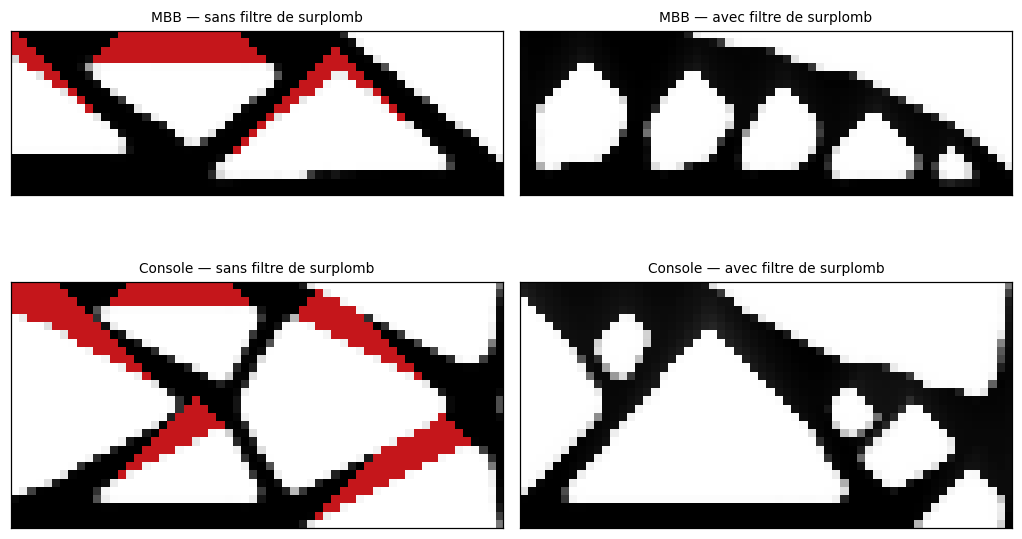

In [11]:
fig, axs = plt.subplots(2, 2, figsize=(9.4, 6.0))
for i, cas in enumerate(CAS):
    for j, surplomb in enumerate((False, True)):
        pb, r, rb = res[(cas, surplomb)]
        montre(axs[i, j], rb, f"{cas} — {'avec' if surplomb else 'sans'} filtre de surplomb")
        b = rb > 0.5
        manque = b & ~exact_support(b)
        axs[i, j].imshow(np.where(manque, 1.0, np.nan).T, origin="lower", cmap="Reds", vmin=0, vmax=1.3, interpolation="nearest")
plt.tight_layout(); plt.show()

**Lecture.** Le filtre fait ce qu'on lui demande : la fraction de matière sans support passe de plusieurs dizaines de pour cent à **zéro**. Les cellules rouges de la ligne de gauche sont ce qu'une imprimante devrait soutenir. En contrepartie la forme est plus raide à construire : la compliance augmente ($+24\,\%$ sur la MBB, $+33\,\%$ sur la console). Une partie de ce surcoût est le prix physique de renoncer aux porte-à-faux et aux bielles plates ; une autre partie est le biais du filtre lisse, on le sépare plus bas.

Les formes avec surplomb sont reconnaissables : plus de bielle presque horizontale, les membrures montent avec des pentes à $45^\circ$ ou plus raides, et la matière est ancrée sur le plateau.

### Et l'OC ?

Le notebook 10 a montré qu'OC échoue silencieusement dès que ses hypothèses (signe des gradients, une contrainte) sont mises à mal. Ici les signes sont bons ($\bar\rho$ est croissant en $\hat\rho$, donc $\partial C/\partial x\le0$ et $\partial V/\partial x\ge0$) et pourtant il se comporte mal : on le trace.

MMA: C final 111.1, C minimal 111.1 à l'itération 299


OC: C final 1055.8, C minimal 117.0 à l'itération 200


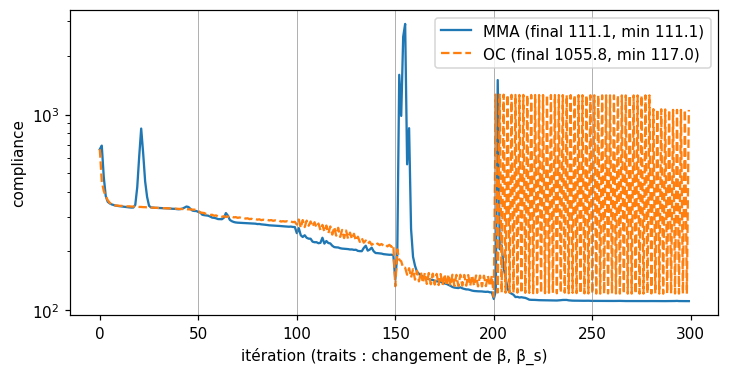

In [12]:
fig, ax = plt.subplots(figsize=(7.6, 3.6))
for opt, style in (("MMA", "-"), ("OC", "--")):
    pb, r, rb = optimise("Console", True, optimiseur=opt)
    C = np.array([h["C"] for h in r.history]); 
    ax.semilogy(C, style, label=f"{opt} (final {C[-1]:.1f}, min {C.min():.1f})")
    print(f"{opt}: C final {C[-1]:.1f}, C minimal {C.min():.1f} à l'itération {C.argmin()}")
for k in range(1, 6): ax.axvline(50 * k, color="gray", lw=0.4)
ax.set_xlabel("itération (traits : changement de β, β_s)"); ax.set_ylabel("compliance"); ax.legend(); plt.show()

OC atteint un bon minimum puis **diverge** (la compliance remonte d'un facteur $10$ en fin de course) : sa mise à jour multiplicative par un facteur de sensibilité a un gain trop élevé quand une variable agit à travers toute une colonne de couches. Rien n'y alerte : l'arrêt est « max_iter ». C'est la raison pour laquelle le projet garde MMA comme optimiseur par défaut dès que le filtre de surplomb est actif.

**Dernière précaution.** La sensibilité à une cellule qui n'est plus supportée est quasi nulle (cône de dépendance, §4) ; une cellule retirée par le filtre ne revient donc que difficilement. L'optimisation avec surplomb dépend du **départ** et du calendrier de $\beta_s$ : on teste deux calendriers et deux fractions volumiques de départ.

In [13]:
print(f"{'calendrier beta_s':>20} {'C final':>9} {'sans support':>13}")
for bs in [(10.0, 80.0), (80.0, 80.0), (10.0, 10.0), (200.0, 200.0)]:
    pb, r, rb = optimise("MBB", True, bs=bs)
    C = float(pb.evaluate(torch.from_numpy(r.x)).terms["C"])
    print(f"{str(bs):>20} {C:>9.1f} {100*non_supporte(rb):>12.1f}%")

   calendrier beta_s   C final  sans support


        (10.0, 80.0)     237.2          0.0%


        (80.0, 80.0)     222.7          0.0%


        (10.0, 10.0)     317.6          0.0%


      (200.0, 200.0)     208.9          0.0%


Le filtre est **toujours** auto-supportant (0 % de cellules sans support), mais pas au même prix. Plus $\beta_s$ est petit, plus le $\mathrm{smax}$ sous-estime le support et plus le filtre **retire de matière au-delà de la règle exacte** : la compliance finale va de $318$ ($\beta_s=10$ constant) à $209$ ($\beta_s=200$ constant), soit un écart de $50\,\%$ qui ne dit rien de la physique et tout du biais $\log n/\beta_s$ accumulé par couche (§4). Le calendrier $10\to80$ du projet est donc **prudent** : il garantit l'auto-support mais surestime le coût de la contrainte. À $\beta_s=200$, le surcoût de la MBB n'est plus que de $9\,\%$ ($209$ contre $192$) ; le calendrier est un réglage à affiner (FORMALISM : « à régler »), et le surcoût de $24\,\%$ cité plus haut est une **borne supérieure** liée à ce réglage. Il faut garder à l'esprit qu'avec $\beta_s$ grand, le gradient est plus raide et l'optimisation moins régulière ; on n'a mesuré ici qu'un seul départ.

## Bilan

| Constat | Où c'est dans le code |
|---|---|
| Règle exacte : une cellule est imprimée si elle est voulue et si une cellule de son stencil du dessous l'est ; seul $45^\circ$ est représentable avec un stencil d'une cellule ; ponts retirés | `exact_support` (oracle), `OverhangParams` |
| Version lisse : $\mathrm{smax}$ (log-somme-exp, biais $\le\log n/\beta_s$) et $\mathrm{smin}_\epsilon$ ; $\bar\rho\le\hat\rho$, croissante, gradient fini y compris pour un champ nul | `smax`, `smin`, `overhang_filter`, C-OVH-01, 07 |
| Stencil en croix en 3D : $45^\circ$ le long des axes, $35^\circ$ le long des diagonales ; le carré donnerait $54{,}7^\circ$ | `shifted_stack`, C-OVH-04 |
| Biais accumulé par couche : erreur $\approx(n_z-1)\log n/\beta_s$ ; la forme lisse n'est pas exacte aux $\beta_s$ de l'optimisation mais sa binarisation est auto-supportante | C-OVH-02, 03 |
| Gradient nul hors du cône à $45^\circ$, non nul dedans (rétropropagation à travers la récurrence de couches) | C-OVH-09 |
| Solide passif suspendu : erreur de configuration | `check_solid_supported`, C-OVH-06 |
| Avec le filtre : $0\,\%$ de cellules sans support ; surcoût de compliance de $24\,\%$ (MBB) à $33\,\%$ (console) avec $\beta_s:10\to80$, mais seulement $9\,\%$ (MBB) avec $\beta_s=200$ : le biais du filtre lisse est une partie du coût | §6 |
| OC diverge avec ce filtre ; MMA reste stable | §6 |

**Limites à retenir.**
- **Un seul angle** : $45^\circ$. L'angle réel d'une imprimante est un paramètre du matériau et de la buse (souvent entre $40^\circ$ et $55^\circ$ selon le refroidissement).
- **Pas de ponts** : le filtre retire des travées horizontales que l'imprimante saurait faire ; c'est conservateur.
- **Axe de fabrication = dernier axe** : choisir l'orientation d'impression, c'est choisir quel axe de la grille est le dernier, avant de lancer l'optimisation. Les leçons 11 et 12 donnent chacune un argument pour cette orientation (raideur anisotrope, auto-support) et ils ne vont pas forcément dans le même sens.
- **Le critère est binaire** : il ne dit rien de la qualité d'une surface inclinée (effet d'escalier), de la tenue d'une paroi fine ni de la vitesse d'impression.
- **Les mesures viennent de deux cas 2D** ; le test 3D est celui du filtre seul, pas d'une optimisation complète.

**Pour expérimenter.** (i) Au §3, mesurez les angles pour un stencil de rayon 2 (non implémenté : écrivez-le) : quels angles devient-il possible de représenter ? (ii) Au §4, tracez la même carte de gradient avec $\beta_s=100$ : le cône garde-t-il sa forme ? (iii) Au §6, retournez la MBB (axe $z$ inversé : `rho[:, ::-1]`) : le coût du surplomb change-t-il ? (iv) Au §6, essayez `OC(move=0.02)` : le déplacement limité corrige-t-il la divergence ?

*Suite : leçon 13 (de la densité à une pièce imprimable). Voir le [plan des leçons](README.md).*